# Customer segmentation of online shopping sessions (K-means)

Slides: [`reports/online_shoppers_clustering_slides.pdf`](../reports/online_shoppers_clustering_slides.pdf).

## 1. Loading and understanding the data
Load the CSV, show the first rows, the column info and summary statistics.

Dataset: [UCI Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset) (CC BY 4.0).


In [ ]:
import pandas as pd
import sys
from pathlib import Path

# Data lives in the repo's data/ folder (see data/README.md).
# In Colab, upload the file to /content/data/ or mount Drive and point DATA_DIR at it.
IN_COLAB = 'google.colab' in sys.modules
DATA_DIR = Path('/content/data') if IN_COLAB else Path('../data')

# Load the dataset
file_path = DATA_DIR / 'online_shoppers_intention.csv'
df = pd.read_csv(file_path)

# Display the first few rows
display(df.head())

# Display dataset information
print("\n--- Dataset Info ---")
print(df.info())

# Display summary statistics
print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


## 2. Data cleaning
Check for missing values and drop duplicate rows.

In [ ]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Drop duplicates if any exist
initial_shape = df.shape
df = df.drop_duplicates()
final_shape = df.shape

print(f"\nDropped {initial_shape[0] - final_shape[0]} duplicate rows.")
print(f"Data shape after cleaning: {final_shape}")

Missing values per column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Dropped 125 duplicate rows.
Data shape after cleaning: (12205, 18)


## 3. Data description


Each row in this dataset represents a single browsing session by a user on the e-commerce website over a 1-year period.

Major Variables:
Administrative, Informational, ProductRelated: The number of different types of pages visited by the user in that session.
Duration: The total time spent (in seconds) on each of these page categories.
BounceRates, ExitRates, PageValues: Google Analytics metrics evaluating the quality and engagement of the pages visited.
SpecialDay: Closeness of the site visiting time to a specific special day (e.g., Mother's Day, Valentine's Day) where a transaction is more likely.
Revenue: The target variable (which we will exclude from clustering) indicating whether the session ended in a purchase.

Count plots for the categorical variables, then the mean and standard deviation of the numeric ones.

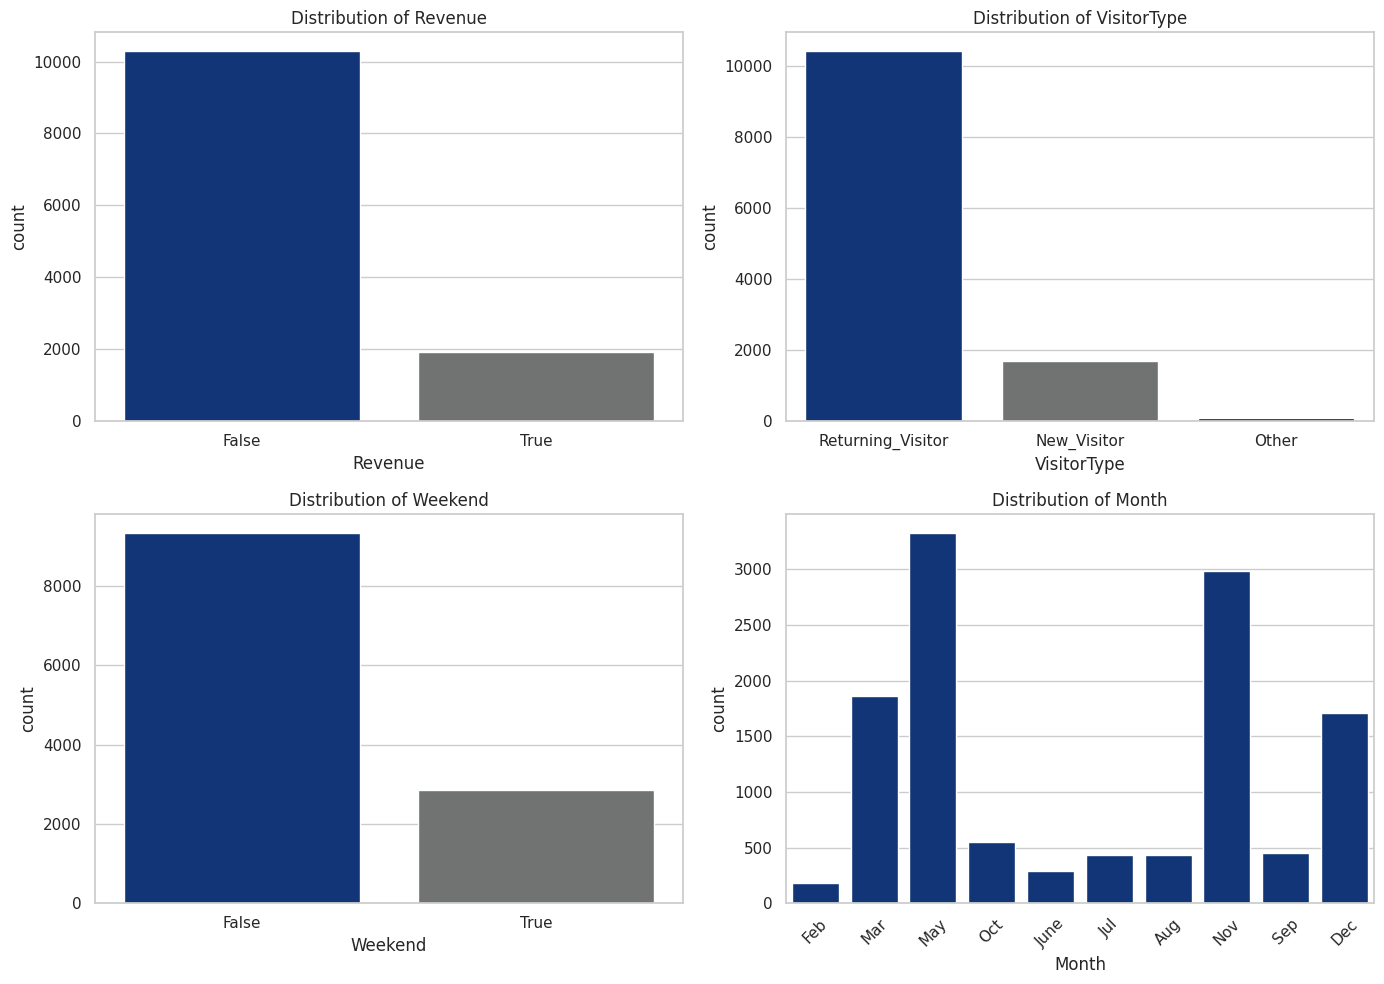


--- Means and Standard Deviations for Quantitative Variables ---


,mean,std
Administrative,2.338878,3.330436
Administrative_Duration,81.646331,177.491845
Informational,0.508726,1.275617
Informational_Duration,34.825454,141.424807
ProductRelated,32.045637,44.593649
ProductRelated_Duration,1206.982457,1919.601400
BounceRates,0.020370,0.045255
ExitRates,0.041466,0.046163
PageValues,5.949574,18.653671
SpecialDay,0.061942,0.199666


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

wl_blue = '#003087'
wl_grey = '#707372'

# Set plot style
sns.set_theme(style="whitegrid")

# Categorical Variables to plot
cat_vars = ['Revenue', 'VisitorType', 'Weekend', 'Month']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, var in enumerate(cat_vars):
    if var == 'Month':
        # Make Month chart all primary blue
        sns.countplot(data=df, x=var, ax=axes[i], color=wl_blue)
    else:
        # Use primary colors for other categorical features
        n_colors = df[var].nunique()
        palette = [wl_blue, wl_grey, '#00194A'][:n_colors] # Adding a darker blue as a safe 3rd option if needed
        sns.countplot(data=df, x=var, hue=var, ax=axes[i], palette=palette, legend=False)

    axes[i].set_title(f'Distribution of {var}')
    axes[i].tick_params(axis='x', rotation=45 if var == 'Month' else 0)

plt.tight_layout()
plt.show()

# Means and standard deviations for quantitative variables
quant_vars = ['Administrative', 'Administrative_Duration', 'Informational',
              'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
              'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

print("\n--- Means and Standard Deviations for Quantitative Variables ---")
display(df[quant_vars].agg(['mean', 'std']).T)

## 4. Data quality and preprocessing

Apply log1p to every clustering feature with skewness above 2, then standardize all of them.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Define clustering features
cluster_cols = ['Administrative', 'Administrative_Duration', 'Informational',
                'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration',
                'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

# Check skewness
print("Skewness of quantitative variables:")
skewness = df[cluster_cols].skew().sort_values(ascending=False)
display(skewness)

# Variables with high skewness (> 2.0 is a reasonable threshold for log transformation in this context)
skewed_cols = skewness[skewness > 2.0].index.tolist()
print(f"\nApplying log1p transformation to highly skewed variables: {skewed_cols}")

# Create a copy for preprocessing
df_processed = df.copy()

# Apply log1p
for col in skewed_cols:
    df_processed[col] = np.log1p(df_processed[col])

# Standardize features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_processed[cluster_cols])

# Convert back to DataFrame for easy handling
df_scaled = pd.DataFrame(scaled_features, columns=cluster_cols, index=df.index)

print("\nPreprocessing complete. Features standardized.")

Skewness of quantitative variables:


,0
Informational_Duration,7.540291
ProductRelated_Duration,7.253161
PageValues,6.350983
Administrative_Duration,5.592152
ProductRelated,4.333419
Informational,4.014173
SpecialDay,3.285902
BounceRates,3.162425
ExitRates,2.234645
Administrative,1.947123



Applying log1p transformation to highly skewed variables: ['Informational_Duration', 'ProductRelated_Duration', 'PageValues', 'Administrative_Duration', 'ProductRelated', 'Informational', 'SpecialDay', 'BounceRates', 'ExitRates']

Preprocessing complete. Features standardized.


## 5. Choosing the number of clusters

Fit K-means for k = 2 to 8 and compare inertia (elbow), silhouette score and Davies-Bouldin score.

,k,Inertia,Silhouette Score,Davies-Bouldin Score
0,2,94265.641829,0.370600,1.167133
1,3,68190.114145,0.411564,0.981278
2,4,56163.926452,0.291731,1.206687
3,5,49787.892973,0.301029,1.120831
4,6,41783.656796,0.333533,1.002488
5,7,38125.813593,0.303901,1.006098
6,8,34508.235010,0.297749,1.165776


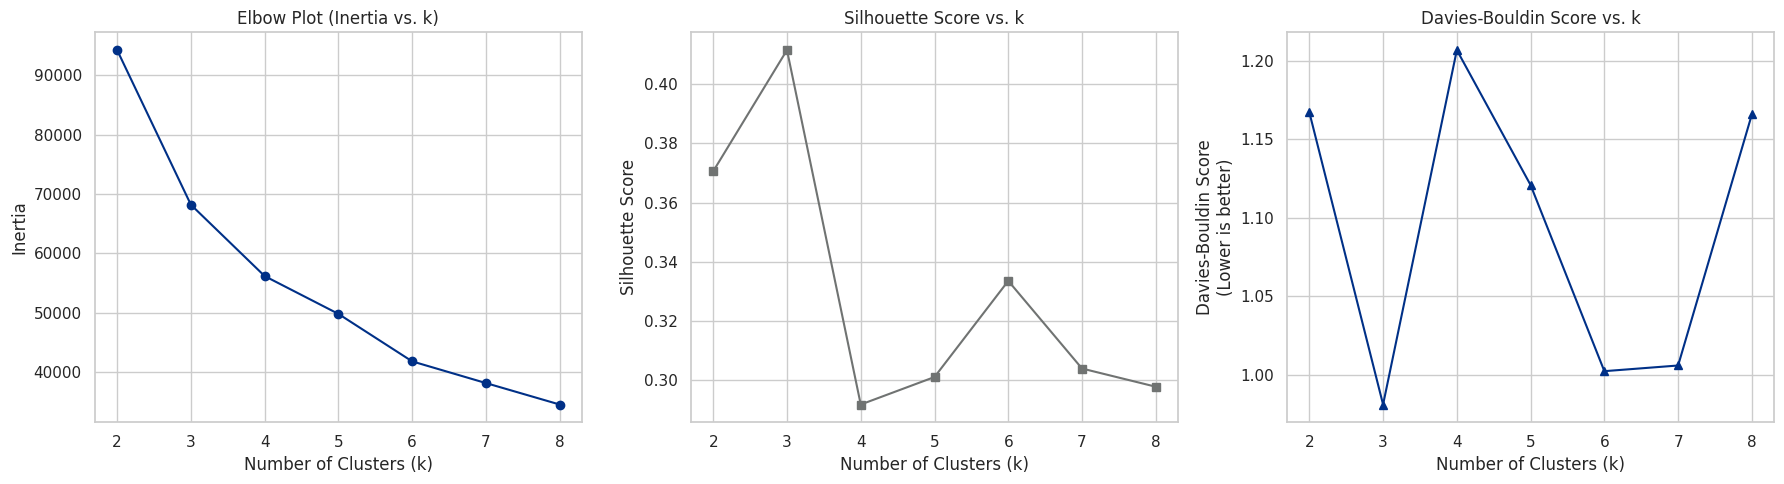

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_values = range(2, 9)
inertias = []
silhouette_scores = []
db_scores = []

# Fit models and collect metrics
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(df_scaled)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(df_scaled, labels))
    db_scores.append(davies_bouldin_score(df_scaled, labels))

# Create summary dataframe
metrics_df = pd.DataFrame({
    'k': k_values,
    'Inertia': inertias,
    'Silhouette Score': silhouette_scores,
    'Davies-Bouldin Score': db_scores
})

display(metrics_df)

wl_blue = '#003087'
wl_grey = '#707372'

# Plotting the metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Inertia (Elbow Plot)
axes[0].plot(k_values, inertias, marker='o', color=wl_blue)
axes[0].set_title('Elbow Plot (Inertia vs. k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

# Silhouette Score
axes[1].plot(k_values, silhouette_scores, marker='s', color=wl_grey)
axes[1].set_title('Silhouette Score vs. k')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

# Davies-Bouldin Score
axes[2].plot(k_values, db_scores, marker='^', color=wl_blue)
axes[2].set_title('Davies-Bouldin Score vs. k')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Score\n(Lower is better)')

plt.tight_layout()
plt.show()

## 6. Final K-means model

K-means with k = 3: cluster sizes, the median profile of each cluster, and a heatmap of standardized cluster means.

--- Cluster Sizes ---


,Number of Sessions,Percentage (%)
Cluster,,
0,8916,73.052028
1,896,7.341254
2,2393,19.606719



--- Cluster Profile (Median Values) ---


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
Cluster,,,,,,,,,,
0,0.0,0.000000,0.0,0.000000,16.0,543.741667,0.000,0.025000,0.0,0.0
1,0.0,0.000000,0.0,0.000000,1.0,0.000000,0.200,0.200000,0.0,0.0
2,5.0,118.903226,2.0,75.666667,45.0,1719.375714,0.004,0.018254,0.0,0.0


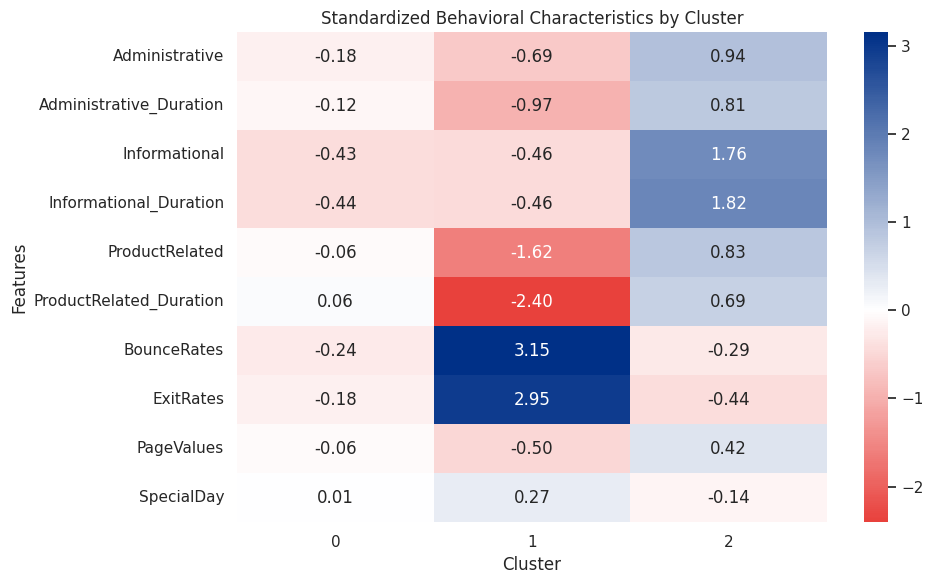

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['Cluster'] = final_kmeans.fit_predict(df_scaled)

# 1. Cluster Sizes
cluster_counts = df['Cluster'].value_counts().sort_index()
cluster_pcts = df['Cluster'].value_counts(normalize=True).sort_index() * 100

size_df = pd.DataFrame({
    'Number of Sessions': cluster_counts,
    'Percentage (%)': cluster_pcts
})
print("--- Cluster Sizes ---")
display(size_df)

# 2. Cluster Profile Table (Original Scale)
print("\n--- Cluster Profile (Median Values) ---")
profile_median = df.groupby('Cluster')[cluster_cols].median()
display(profile_median)

# 3. Standardized Cluster Means
df_scaled['Cluster'] = df['Cluster']
profile_standardized = df_scaled.groupby('Cluster')[cluster_cols].mean()

# Diverging colormap (red to white to blue)
wl_cmap = LinearSegmentedColormap.from_list('wl_diverging', ['#E10600', '#FFFFFF', '#003087'])

# 4. Heatmap of Standardized Means
plt.figure(figsize=(10, 6))
sns.heatmap(profile_standardized.T, cmap=wl_cmap, center=0, annot=True, fmt=".2f")
plt.title('Standardized Behavioral Characteristics by Cluster')
plt.ylabel('Features')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

## 7. Business validation using revenue

Conversion rate, share of returning visitors and share of weekend visits per cluster, compared with the overall conversion rate.

Overall Dataset Conversion Rate: 15.63%

--- Business Validation by Cluster ---


,Sessions,Pct_of_Total,Conversion_Rate,Returning_Visitor_Pct,Weekend_Pct
Cluster,,,,,
0,8916,73.05,14.65,83.32,22.91
1,896,7.34,0.56,95.20,18.53
2,2393,19.61,24.95,89.80,27.16


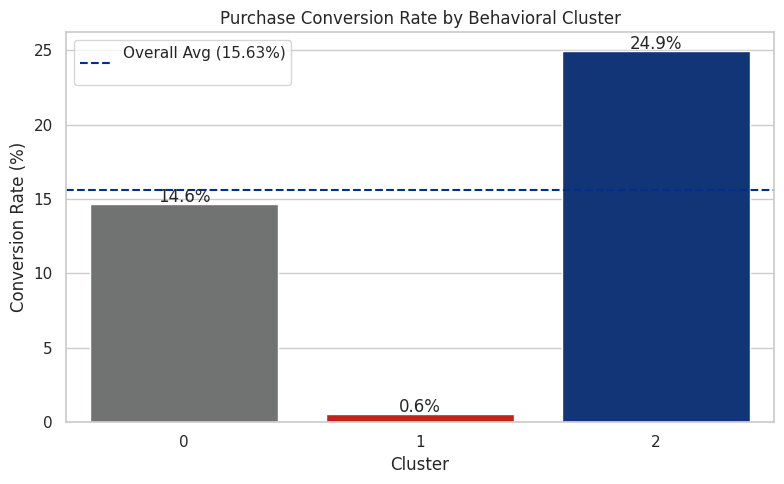

In [ ]:
# Overall Conversion Rate
overall_conversion = df['Revenue'].mean() * 100
print(f"Overall Dataset Conversion Rate: {overall_conversion:.2f}%\n")

# Cluster Conversion Rates and Composition
val_df = df.groupby('Cluster').agg(
    Sessions=('Revenue', 'count'),
    Conversion_Rate=('Revenue', lambda x: x.mean() * 100),
    Returning_Visitor_Pct=('VisitorType', lambda x: (x == 'Returning_Visitor').mean() * 100),
    Weekend_Pct=('Weekend', lambda x: x.mean() * 100)
)

val_df['Pct_of_Total'] = (val_df['Sessions'] / len(df)) * 100
val_df = val_df[['Sessions', 'Pct_of_Total', 'Conversion_Rate', 'Returning_Visitor_Pct', 'Weekend_Pct']]

print("--- Business Validation by Cluster ---")
display(val_df.round(2))

wl_blue = '#003087'
wl_palette = ['#707372', '#E10600', '#003087'] # Grey, Vibrant Red, Blue

# Bar chart of Conversion Rates
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=val_df.index, y='Conversion_Rate', data=val_df, hue=val_df.index, palette=wl_palette, legend=False)
plt.axhline(y=overall_conversion, color=wl_blue, linestyle='--', label=f'Overall Avg ({overall_conversion:.2f}%)\n')
plt.title('Purchase Conversion Rate by Behavioral Cluster')
plt.ylabel('Conversion Rate (%)')
plt.xlabel('Cluster')
plt.legend()

# Add value labels on bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 8. Principal component analysis (PCA)

Explained variance, scree plot, loadings of the first two components, and the clusters projected onto them.

PC1 Explained Variance: 42.48%
PC2 Explained Variance: 17.44%
Cumulative Variance (First 2 PCs): 59.93%



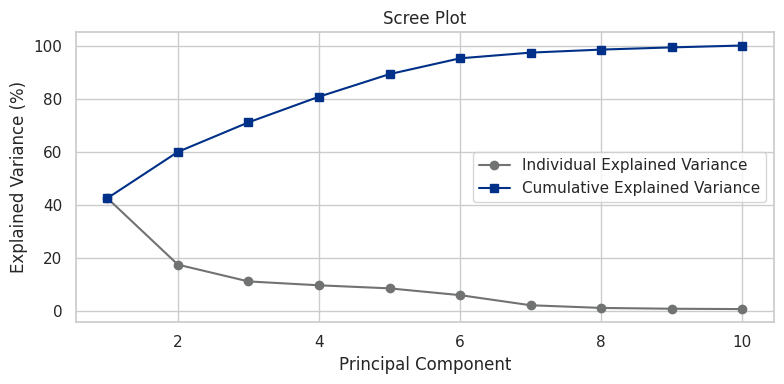


--- PCA Loadings (First 2 Components) ---


,PC1,PC2
Administrative,0.323741,0.244193
Administrative_Duration,0.336788,0.161572
Informational,0.284821,0.511235
Informational_Duration,0.284085,0.506808
ProductRelated,0.391236,-0.103134
ProductRelated_Duration,0.407479,-0.250988
BounceRates,-0.331219,0.423316
ExitRates,-0.383878,0.377740
PageValues,0.196791,0.022601
SpecialDay,-0.070985,-0.004689


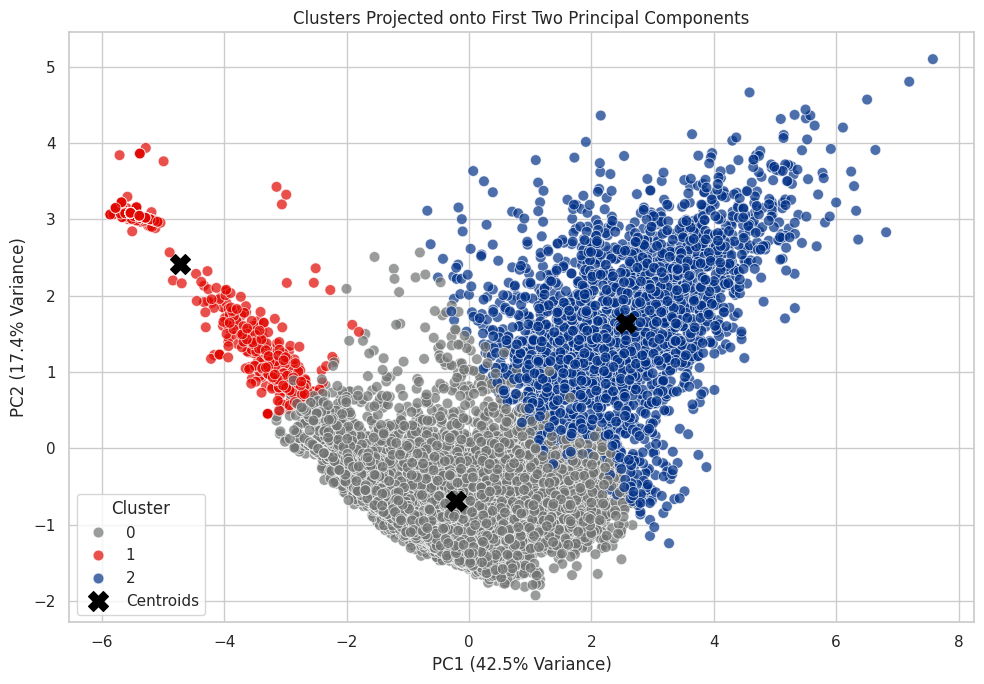

In [ ]:
from sklearn.decomposition import PCA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Drop the 'Cluster' column before applying PCA
X_pca = df_scaled.drop(columns=['Cluster'])

pca = PCA(random_state=42)
pca_components = pca.fit_transform(X_pca)

# Explained Variance
exp_var = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)

print(f"PC1 Explained Variance: {exp_var[0]:.2f}%")
print(f"PC2 Explained Variance: {exp_var[1]:.2f}%")
print(f"Cumulative Variance (First 2 PCs): {cum_var[1]:.2f}%\n")

# W&L Theme Colors
wl_blue = '#003087'
wl_grey = '#707372'
wl_vibrant_red = '#E10600'
wl_palette = ['#707372', '#E10600', '#003087'] # Cluster matching palette
wl_cmap = LinearSegmentedColormap.from_list('wl_diverging', [wl_vibrant_red, '#FFFFFF', wl_blue])

# Scree Plot
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(exp_var) + 1), exp_var, marker='o', label='Individual Explained Variance', color=wl_grey)
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='s', label='Cumulative Explained Variance', color=wl_blue)
plt.title('Scree Plot')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.legend()
plt.tight_layout()
plt.show()

# PCA Loadings
loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f'PC{i+1}' for i in range(len(cluster_cols))],
    index=cluster_cols
)

print("\n--- PCA Loadings (First 2 Components) ---")
display(loadings[['PC1', 'PC2']].style.background_gradient(cmap=wl_cmap, axis=0))

# PCA Scatterplot
plt.figure(figsize=(10, 7))
sns.scatterplot(x=pca_components[:, 0], y=pca_components[:, 1], hue=df['Cluster'], palette=wl_palette, s=60, alpha=0.7)

# Calculate Centroids in PCA space by re-running KMeans purely on X_pca to avoid dimensional mismatch
final_kmeans_pca = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
final_kmeans_pca.fit(X_pca)
centroids_df = pd.DataFrame(final_kmeans_pca.cluster_centers_, columns=cluster_cols)
centroids_pca = pca.transform(centroids_df)
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1], c='black', s=200, marker='X', label='Centroids')

plt.title('Clusters Projected onto First Two Principal Components')
plt.xlabel(f'PC1 ({exp_var[0]:.1f}% Variance)')
plt.ylabel(f'PC2 ({exp_var[1]:.1f}% Variance)')
plt.legend(title='Cluster')
plt.grid(True)
plt.tight_layout()
plt.show()

## 9. Cluster interpretation

Based on the empirical cluster profiles and standardized means, here is the behavioral interpretation of the three clusters:

### Cluster 0: "Casual Browsers"
* **Defining Characteristics:** This is the largest segment. They have slightly below-average page views and durations across all categories. Their bounce and exit rates are relatively low, meaning they are browsing the site normally without leaving immediately, but they aren't deeply engaged.
* **Relative Conversion Rate:** 14.6% (Slightly below the overall average of 15.6%)
* **Business Interpretation:** These are typical window-shoppers. They explore a few product pages but do not exhibit the heavy research behavior of high-intent buyers.
* **Recommended Action:** Implement personalized product recommendations and targeted exit-intent pop-ups offering small discounts to incentivize these casual browsers to complete a purchase.

### Cluster 1: "Quick Exiters"
* **Defining Characteristics:** Extremely high Bounce Rates (+3.15 standard deviations) and Exit Rates (+2.95 standard deviations). They view almost zero product pages (median = 1) and spend nearly zero time on the site.
* **Relative Conversion Rate:** 0.6% (Extremely low)
* **Business Interpretation:** This traffic represents "bounces." They could be users who clicked an ad by mistake, bots, or visitors who immediately realized the site did not have what they wanted.
* **Recommended Action:** Investigate the marketing channels driving this traffic. Reallocate ad spend away from campaigns that yield high bounce rates to avoid paying for unqualified traffic.

### Cluster 2: "High-Intent Shoppers"
* **Defining Characteristics:** Highly engaged visitors. They view significantly more Administrative, Informational, and Product-Related pages (median of 45 product pages vs. 16 for Casual Browsers) and spend much more time on the site.
* **Relative Conversion Rate:** 24.9% (Significantly higher than average)
* **Business Interpretation:** These users are performing deep research, reading informational pages, and comparing many products. Their extensive behavioral footprint strongly signals purchase intent.
* **Recommended Action:** Ensure the checkout process is frictionless. Provide proactive live chat support to answer final questions, and utilize retargeting ads for users in this segment who abandon their carts, as they represent the highest potential ROI.

## 10. Limitations and ethics

**Methodological and Business Limitations:**
* **Session vs. Customer:** This dataset records *sessions*, not unique long-term customers. A single user might be a "Quick Exiter" on mobile in the morning and a "High-Intent Shopper" on a desktop in the evening. We are clustering visits, not people.
* **Snapshot in Time:** The data reflects a specific business during a specific time period. Consumer behavior changes due to seasonality, site redesigns, and macroeconomic factors.
* **K-Means Assumptions:** K-means assumes clusters are approximately spherical and equally sized, which is rarely perfectly true in real-world behavioral data. The results are highly dependent on the choice of $k$, distance metric, and feature scaling.
* **PCA Information Loss:** Our 2D PCA plot captures ~60% of the total variance. While useful for visualization, it means 40% of the behavioral nuance is hidden, which is why clusters may appear slightly overlapping in 2D despite being mathematically separated in 10-dimensional space.
* **No Causality:** These segments describe behavioral correlations, not causality. High engagement does not *cause* a purchase; rather, purchase intent drives high engagement.

**Ethical Considerations:**
* **Privacy:** Tracking granular behavioral metrics (durations, bounce rates, operating systems) requires user consent. E-commerce platforms must adhere to privacy frameworks like GDPR or CCPA, ensuring users can opt out of tracking.
* **Targeting:** While behavioral segmentation is standard marketing practice, businesses must ensure that "optimizing for revenue" does not lead to predatory practices, such as hiding discounts from "High-Intent" shoppers because the algorithm assumes they will buy anyway.

## 11. Business conclusions

* **What major behavioral segments were discovered?**
  We discovered three distinct browsing profiles: Casual Browsers (average engagement), Quick Exiters (bounces), and High-Intent Shoppers (deep engagement).
* **How are they behaviorally different?**
  They differ primarily in engagement depth (Product-Related page views and total duration) and site friction (Bounce and Exit rates).
* **Which clusters had relatively high or low purchase conversion rates?**
  The "High-Intent Shoppers" cluster had an exceptionally high conversion rate (24.9%), while the "Quick Exiters" almost never converted (0.6%).
* **What business decisions could these results potentially inform?**
  These insights can guide digital marketing spend (cutting funding to sources driving Quick Exiters), UI/UX improvements (simplifying the path to purchase for Casual Browsers), and customer support resource allocation (prioritizing High-Intent Shoppers).
* **How confident should management be in the findings?**
  Management can be highly confident in the existence of these behavioral groups, as evidenced by a solid Silhouette Score and stark differences in actual conversion rates. However, they should keep in mind that these apply to sessions, not unique lifetime customers.

## 12. Marketing ROI: blanket ads vs targeting

Assumptions: a $10,000 budget and $5 per ad shown, so 2,000 people reached. Compare showing ads to random visitors (overall conversion rate) with showing them only to the high-intent cluster (Cluster 2).

--- Ad Campaign Projections ($10,000 Budget) ---


,Strategy,Conversion Rate,People Reached,Expected Conversions,Cost Per Acquisition (CPA)
0,Blanket (All Visitors),15.63%,2000,312,31.98
1,Targeted (High-Intent Only),24.95%,2000,498,20.04


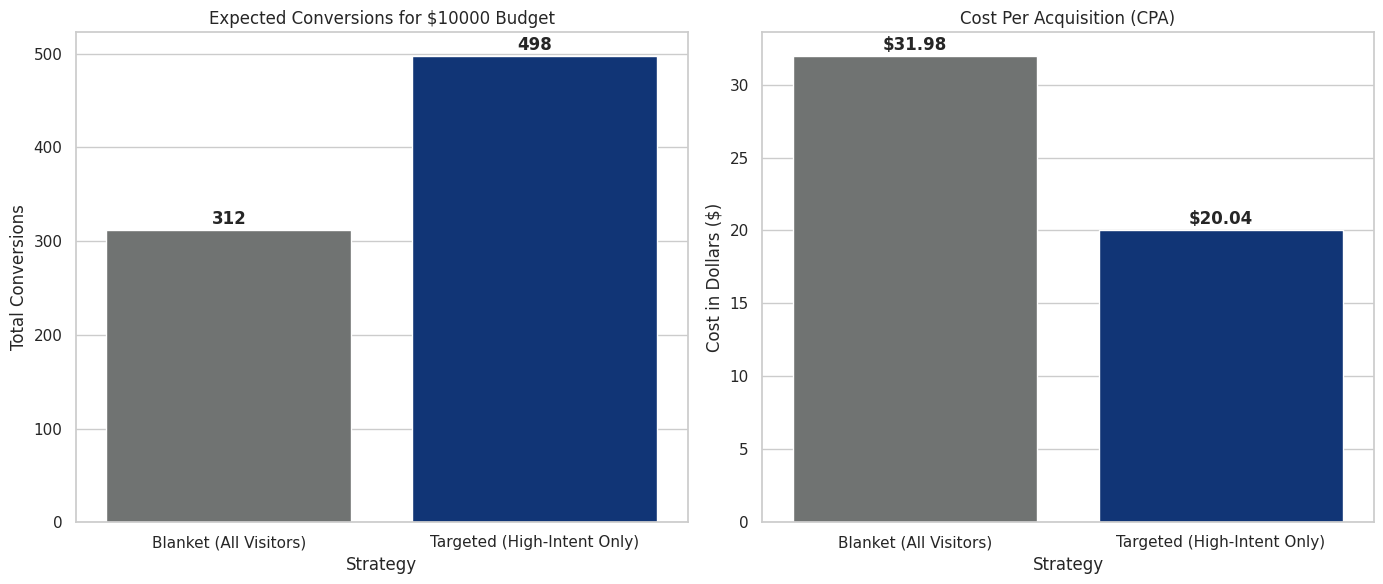

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Assumptions
budget = 10000  # Total budget in dollars
cost_per_person = 5  # Cost to advertise to one person
people_reached = budget / cost_per_person

# 1. Blanket Strategy Metrics (Overall Average)
blanket_conversion_rate = overall_conversion / 100
blanket_conversions = people_reached * blanket_conversion_rate
blanket_cpa = budget / blanket_conversions

# 2. Targeted Strategy Metrics (Cluster 2 Only)
targeted_conversion_rate = val_df.loc[2, 'Conversion_Rate'] / 100
targeted_conversions = people_reached * targeted_conversion_rate
targeted_cpa = budget / targeted_conversions

# Summarize in a DataFrame
roi_df = pd.DataFrame({
    'Strategy': ['Blanket (All Visitors)', 'Targeted (High-Intent Only)'],
    'Conversion Rate': [f"{blanket_conversion_rate*100:.2f}%", f"{targeted_conversion_rate*100:.2f}%"],
    'People Reached': [int(people_reached), int(people_reached)],
    'Expected Conversions': [int(blanket_conversions), int(targeted_conversions)],
    'Cost Per Acquisition (CPA)': [blanket_cpa, targeted_cpa]
})

print("Ad Campaign Projections ($10,000 Budget)")
display(roi_df.round(2))

# Visualization
wl_blue = '#003087'
wl_grey = '#707372'
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Total Conversions
sns.barplot(x='Strategy', y='Expected Conversions', data=roi_df, hue='Strategy', palette=[wl_grey, wl_blue], legend=False, ax=axes[0])
axes[0].set_title(f'Expected Conversions for ${budget} Budget')
axes[0].set_ylabel('Total Conversions')
# Annotate bars
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')

# Plot 2: Cost Per Acquisition (CPA)
sns.barplot(x='Strategy', y='Cost Per Acquisition (CPA)', data=roi_df, hue='Strategy', palette=[wl_grey, wl_blue], legend=False, ax=axes[1])
axes[1].set_title('Cost Per Acquisition (CPA)')
axes[1].set_ylabel('Cost in Dollars ($)')
# Annotate bars
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()